# 04 — A €50 thickness gauge

Companion notebook to *Measuring steel with sound* (`docs/substack/04-measuring-steel-with-sound.md`).
pic0rick python library **v0.1.8**. Offline by default: 5-step 1018-steel calibration block,
5 MHz contact probe, c = 5950 m/s.

In [1]:
# --- common setup: find the repo, import the pic0rick library, pin the version
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

REPO = next(p for p in pathlib.Path.cwd().resolve().parents if (p / "python" / "pic0rick").is_dir())
sys.path.insert(0, str(REPO / "python"))
import pic0rick

WRITTEN_FOR = "0.1.8"   # pic0rick python library version this notebook was written against
print("pic0rick python library:", pic0rick.__version__, "(notebook written for", WRITTEN_FOR + ")")
if pic0rick.__version__ != WRITTEN_FOR:
    print("WARNING: library version differs -- the API may have moved, check python/Readme.md")

FIG = pathlib.Path("../images"); FIG.mkdir(exist_ok=True)
DATA = REPO / "docs" / "data"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3})

LIVE = False   # set True with a pic0rick (firmware -DDSP build, v0.1.11+) plugged in

pic0rick python library: 0.1.8 (notebook written for 0.1.8)


In [2]:
from pic0rick.ndt_acquisition import UltrasonicAcquisition, load_h5
H5 = DATA / "calibration_block_5steps_1018steel.h5"
C_STEEL = 5950.0   # longitudinal speed of sound in 1018 steel [m/s]
acqs = load_h5(str(H5))

def shot(thickness_mm, gain):
    if LIVE:
        a = UltrasonicAcquisition.from_probe(Fech=60e6, gain=gain, pon=95, poff=95, damp=6000,
                                             target=f"steel ~{thickness_mm}mm", h5_path="thickness.h5")
    else:
        a = next(x for x in acqs if x.pon == 95 and x.gain == gain and f"~{thickness_mm:.1f}mm" in x.target)
    a.piezo_central_freq, a.piezo_bandwidth = 5e6, 2e6
    return a

## 1. The principle

A pulse bounces between the probe face and the back wall. Successive back-wall echoes are spaced by
the round-trip time **Δt = 2·d / c**, so **d = c·Δt / 2**. Measuring the *spacing* between echoes
(rather than the time of the first one) cancels the probe delay line and couplant thickness.

In [3]:
for d in (10, 15, 20, 25):
    print(f"{d} mm steel -> expected Δt = {2 * d * 1e-3 / C_STEEL * 1e6:.2f} µs")

10 mm steel -> expected Δt = 3.36 µs
15 mm steel -> expected Δt = 5.04 µs
20 mm steel -> expected Δt = 6.72 µs
25 mm steel -> expected Δt = 8.40 µs


## 2. 10 mm step

echo times [µs]: [37.45 40.8  44.18 47.55 50.97 54.3  57.62]
measured Δt 3.361 µs -> thickness 9.999 mm


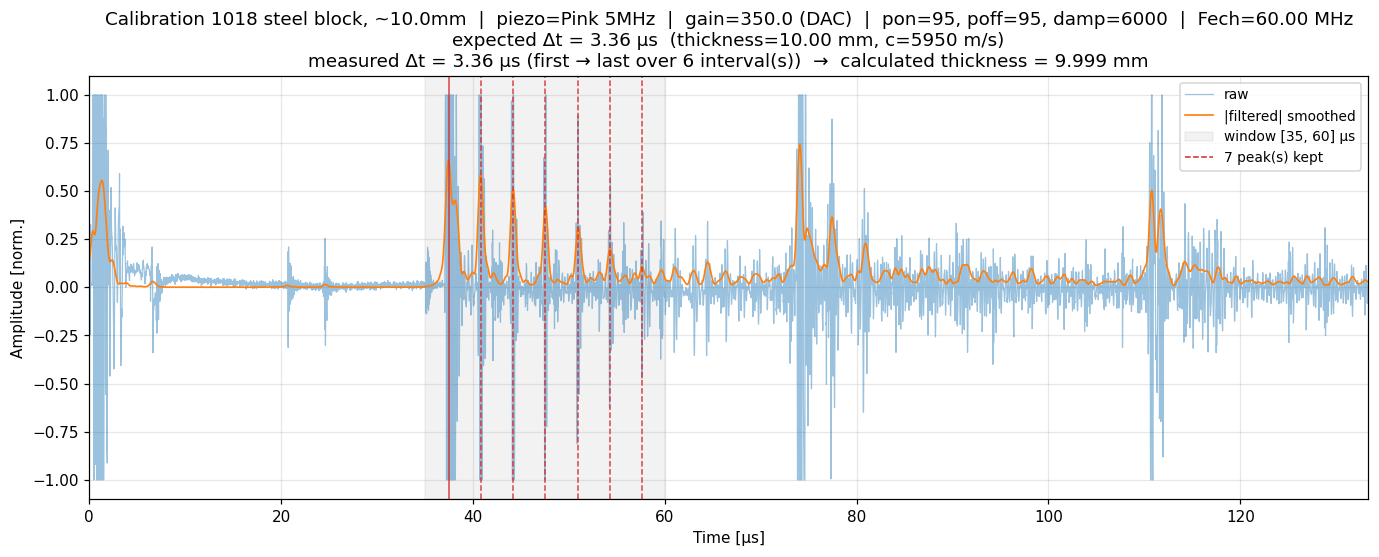

In [4]:
a10 = shot(10.0, 350)
r10 = a10.detect_echoes(start_us=35, end_us=60, target_thickness=0.010, speed_of_sound=C_STEEL,
                        smooth=15, smooth_kernel=7)
r10["figure"].savefig(FIG / "04-echoes-10mm.png")
print("echo times [µs]:", np.round(r10["peak_times_us"], 2))
print("measured Δt %.3f µs -> thickness %.3f mm" % (r10["measured_dt_us"], r10["calculated_thickness"] * 1e3))

## 3. 15 mm and 25 mm steps

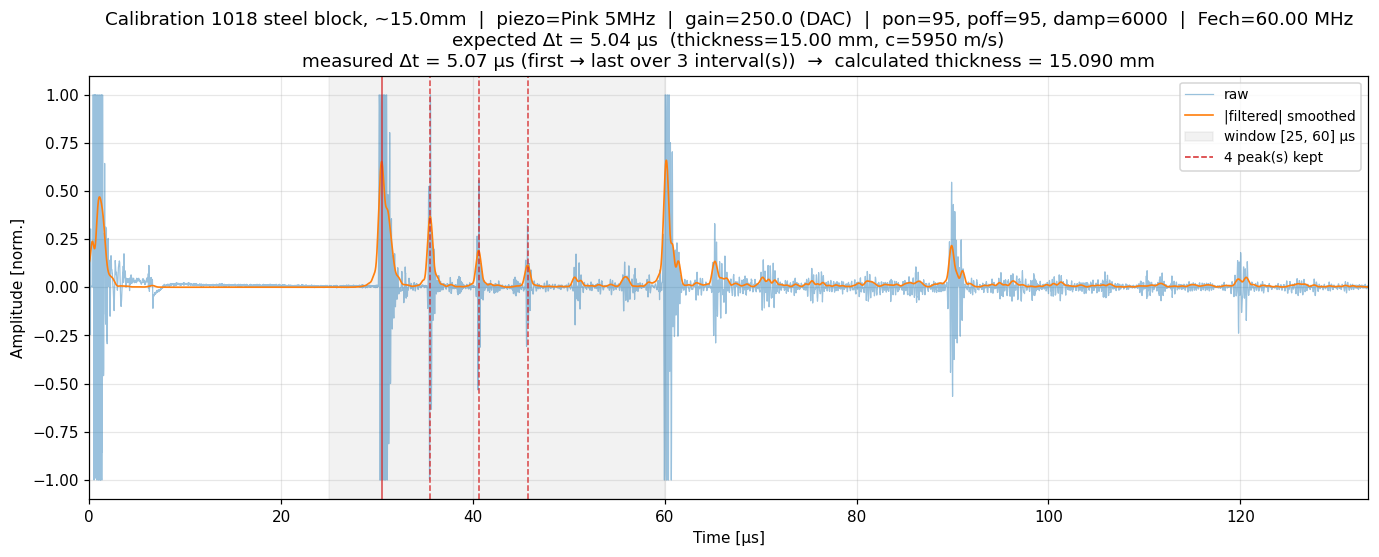

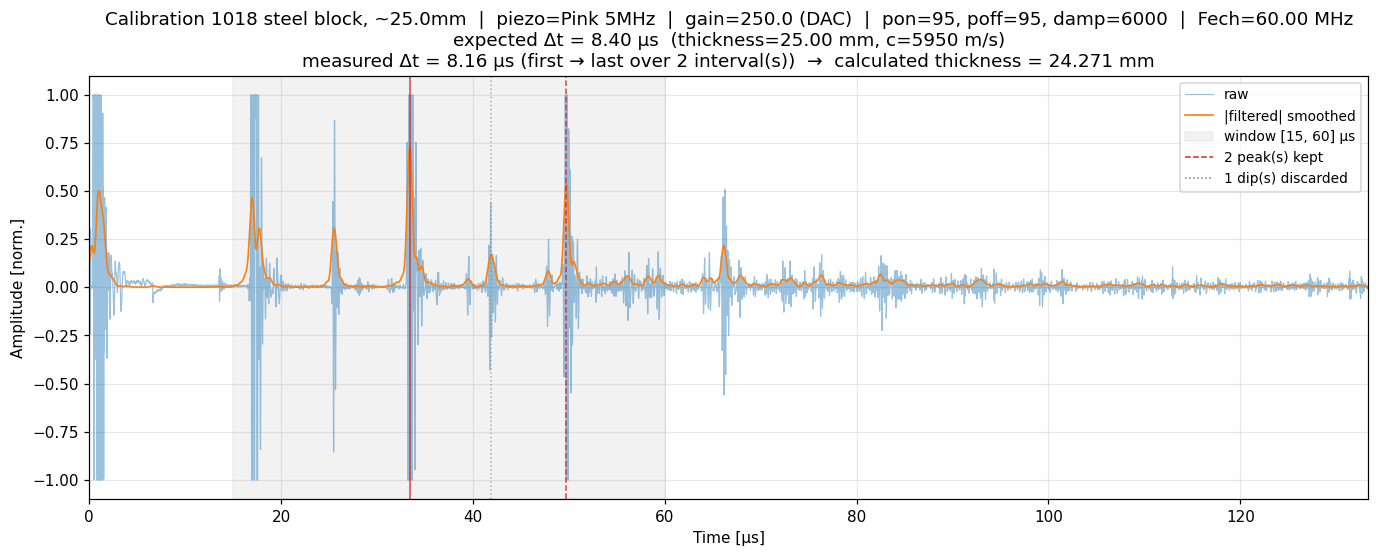

In [5]:
a15 = shot(15.0, 250)
r15 = a15.detect_echoes(start_us=25, end_us=60, target_thickness=0.015, speed_of_sound=C_STEEL,
                        smooth=15, smooth_kernel=7)
r15["figure"].savefig(FIG / "04-echoes-15mm.png")
a25 = shot(25.0, 250)
r25 = a25.detect_echoes(start_us=15, end_us=60, target_thickness=0.025, speed_of_sound=C_STEEL,
                        smooth=15, smooth_kernel=7)
r25["figure"].savefig(FIG / "04-echoes-25mm.png")

## 4. The cautionary 20 mm shot

On the 20 mm step the detector, seeded with Δt = 6.72 µs, latches onto a train spaced ≈5 µs — the
15 mm period. The probe face was most likely straddling the 15/20 mm step edge. The plot shows it.

echo times [µs]: [30.47 35.53 45.68]


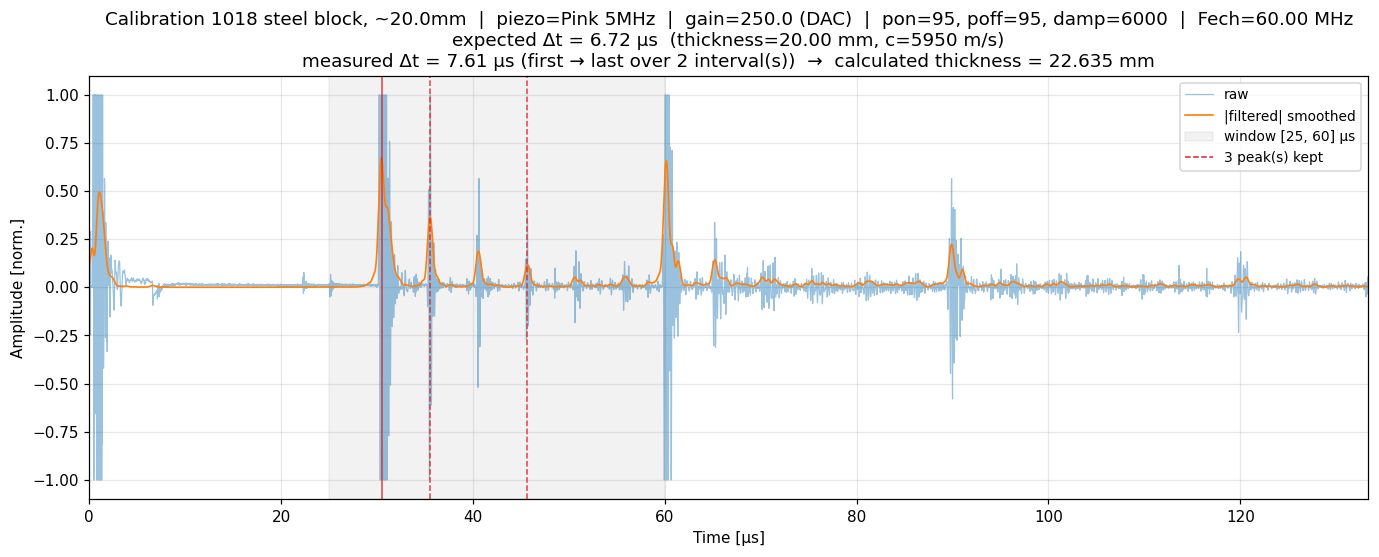

In [6]:
a20 = shot(20.0, 250)
r20 = a20.detect_echoes(start_us=25, end_us=60, target_thickness=0.020, speed_of_sound=C_STEEL,
                        smooth=15, smooth_kernel=7)
r20["figure"].savefig(FIG / "04-echoes-20mm.png")
print("echo times [µs]:", np.round(r20["peak_times_us"], 2))

## 5. Summary

 nominal  Δt meas   d meas   error
    10 mm   3.36µs  10.00mm  -0.00mm
    15 mm   5.07µs  15.09mm  +0.09mm
    20 mm   7.61µs  22.63mm  +2.63mm
    25 mm   8.16µs  24.27mm  -0.73mm


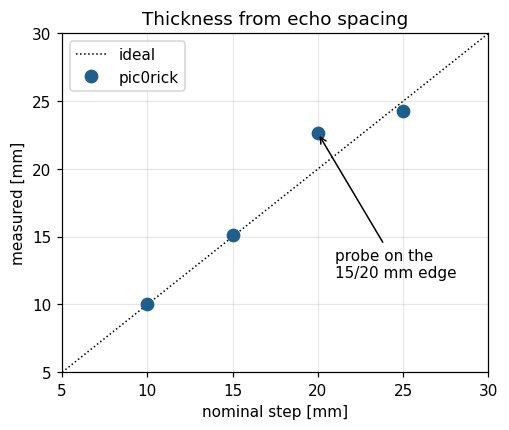

In [7]:
res = [(10, r10), (15, r15), (20, r20), (25, r25)]
print(f"{'nominal':>8} {'Δt meas':>8} {'d meas':>8} {'error':>7}")
for d, r in res:
    dm = r["calculated_thickness"] * 1e3
    print(f"{d:6d} mm {r['measured_dt_us']:6.2f}µs {dm:6.2f}mm {dm - d:+6.2f}mm")

fig, ax = plt.subplots(figsize=(5, 4))
nom = np.array([d for d, _ in res]); meas = np.array([r["calculated_thickness"] * 1e3 for _, r in res])
ax.plot([5, 30], [5, 30], "k:", lw=1, label="ideal")
ax.plot(nom, meas, "o", ms=8, color="#1f5f8b", label="pic0rick")
ax.annotate("probe on the\n15/20 mm edge", xy=(20, meas[2]), xytext=(21, 12), arrowprops=dict(arrowstyle="->"))
ax.set(xlabel="nominal step [mm]", ylabel="measured [mm]", title="Thickness from echo spacing", xlim=(5, 30), ylim=(5, 30))
ax.legend()
fig.savefig(FIG / "04-summary.png")